1. Setup & Imports: Load necessary libraries and define the text file to be processed.

In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import re
from IPython.display import display

# ==========================================
# Text file to process
# ==========================================
filename = "JKA_DMA_20261028_JZ092v10_temprump1Hz-80to200.txt"

2. Extract Metadata & Save Details Table
Extract the experiment parameters from the `.txt` header, display them as a table in Jupyter, and save them as a high-quality JPG image.

In [73]:
# Read the file line by line to extract the header metadata
metadata = {}
with open(filename, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        # Stop reading once we reach the main data block to save memory
        if line.startswith('Data point'):
            break 
        
        parts = line.split('\t')
        if len(parts) >= 2:
            key = parts[0].strip()
            val = parts[1].strip()
            metadata[key] = val

# --- NEW: Extracting the hidden variables using Regex ---
step1_text = metadata.get('Step 1', '')
step2_text = metadata.get('Step 2', '')

# We define rules to find the exact numbers hidden in the long text strings
re_preload = re.search(r'Initial/preload force ([\d\.e\-]+ N)', step1_text)
re_strain = re.search(r'Strain ([\d\.]+ %)', step2_text)
re_frequency = re.search(r'Frequency ([\d\.]+ Hz)', step2_text)
re_ramp_range = re.search(r'Ramp from (.*? °C to .*? °C)', step2_text)
re_ramp_rate = re.search(r'Ramp rate ([\d\.]+ °C/min)', step2_text)

# We add them manually to our metadata dictionary if they were found
if re_preload: metadata['Initial/preload force'] = re_preload.group(1)
if re_strain: metadata['Strain'] = re_strain.group(1)
if re_frequency: metadata['Frequency'] = re_frequency.group(1)
if re_ramp_range: metadata['Ramp'] = re_ramp_range.group(1)
if re_ramp_rate: metadata['Ramp rate'] = re_ramp_rate.group(1)

# Define the exact parameters we want to extract for the image
# Now including the new ones!
parametros_deseados = [
    'Instrument name', 'Name', 
    'Procedure name', 'Length', 'Width', 'Thickness',
    'Initial/preload force', 'Strain', 'Frequency', 'Ramp', 'Ramp rate'
]

extracted_data = []
for param in parametros_deseados:
    if param in metadata:
        # Map to your preferred display names
        display_name = param
        if param == 'File name': display_name = 'Filename'
        if param == 'Name': display_name = 'Sample name'
        extracted_data.append((display_name, metadata[param]))

df_table = pd.DataFrame(extracted_data, columns=['Parameter', 'Value'])
df_table = df_table.drop_duplicates(subset=['Parameter'])

# Draw and format the table
# Note: I increased the height of the figure slightly to (10, 5) to fit the new rows
fig_table, ax_table = plt.subplots(figsize=(10, 5))
ax_table.axis('off')

table = ax_table.table(
    cellText=df_table.values, 
    colLabels=df_table.columns, 
    loc='center', 
    cellLoc='left'
)

# Auto-adjust column widths based on text length
table.auto_set_column_width(col=list(range(len(df_table.columns))))
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1, 1.5) 

# Format the header row
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold', color='white', fontsize=13)
        cell.set_facecolor('#4c72b0')
    cell.PAD = 0.05 

plt.title('Experiment Details', fontsize=16, weight='bold', pad=15)
details_image_name = filename.rsplit('.', 1)[0] + '_details.jpg'

plt.tight_layout()
plt.savefig(details_image_name, format='jpg', dpi=300, bbox_inches='tight', facecolor='white')
plt.close(fig_table)

print(f"Details table successfully saved as: {details_image_name}")
# Display the table directly in the Jupyter Notebook
display(df_table)

Details table successfully saved as: JKA_DMA_20261028_JZ092v10_temprump1Hz-80to200_details.jpg


,Parameter,Value
0,Instrument name,DMA850-01328
1,Sample name,JKA_DMA_20261028_JZ092v10_temprump1Hz-80to200
2,Procedure name,Oscillation Temperature Ramp
3,Length,4.83426 mm
4,Width,2.35 mm
5,Thickness,0.03 mm
6,Initial/preload force,1.0e-3 N
7,Strain,0.01 %
8,Frequency,1.0 Hz
9,Ramp,-80 °C to 200 °C


3. Load & Inspect Data
Isolate the numerical data section within the `.txt` file, convert it into a Pandas DataFrame, and display the available columns to ensure it loaded correctly.

In [75]:
# 1. Open the file and read lines
with open(filename, 'r', encoding='utf-8') as f:
    lines = f.readlines()

header_line_index = -1
data_start_index = -1

# 2. Find the row index where variables and actual data start
for i, line in enumerate(lines):
    if line.startswith('Variables\t'):
        header_line_index = i
    elif line.startswith('Data point\t'):
        data_start_index = i
        break

# 3. Parse the data block
headers = lines[header_line_index].strip().split('\t')[1:] 
data_lines = [line.strip().split('\t')[1:] for line in lines[data_start_index:] if line.startswith('Data point\t')]

df_clean = pd.DataFrame(data_lines, columns=headers)

# 4. Convert all parsed string data into numerical values
for col in df_clean.columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# ==========================================
# 5. FULL DATA PREVIEW
# ==========================================
# Force Pandas to show all columns horizontally without hiding them with "..."
pd.set_option('display.max_columns', None)

print(f"Total rows successfully loaded: {len(df_clean)}")
print(f"Total variables (columns) found: {len(df_clean.columns)}")
print("\n--- LIST OF ALL AVAILABLE PARAMETERS ---")
print(df_clean.columns.tolist())

print("\n--- PREVIEW OF THE RAW DATA (FIRST 15 ROWS) ---")
# Display the first 15 rows showing ALL columns horizontally
display(df_clean.head(15))

Total rows successfully loaded: 1356
Total variables (columns) found: 38

--- LIST OF ALL AVAILABLE PARAMETERS ---
['Run time', 'Temperature', 'Angular frequency', 'Oscillation displacement (cmd)', 'Axial force', 'Oscillation force', 'Oscillation displacement', 'Raw phase (Axial displacement)', 'Delta length', 'Oscillation Force (Drive)', 'Drive Position', 'Temperature set point', 'Oscillation strain', 'Oscillation strain (cmd)', 'Oscillation stress', 'Step time', 'Time', 'Status bits', 'Status bits 2', 'Normal transducer', 'Storage modulus', 'Loss modulus', 'Phase angle', 'Strain ratio', 'Pretension ratio', 'Stiffness', 'Oscillation displacement (drive', 'Position', 'Length', 'Strain constant (linear)', 'Date and time', '1/temperature', 'Frequency', 'Tan(delta)', 'Complex modulus', 'Complex compliance', 'Storage compliance', 'Loss compliance']

--- PREVIEW OF THE RAW DATA (FIRST 15 ROWS) ---


,Run time,Temperature,Angular frequency,Oscillation displacement (cmd),Axial force,Oscillation force,Oscillation displacement,Raw phase (Axial displacement),Delta length,Oscillation Force (Drive),Drive Position,Temperature set point,Oscillation strain,Oscillation strain (cmd),Oscillation stress,Step time,Time,Status bits,Status bits 2,Normal transducer,Storage modulus,Loss modulus,Phase angle,Strain ratio,Pretension ratio,Stiffness,Oscillation displacement (drive,Position,Length,Strain constant (linear),Date and time,1/temperature,Frequency,Tan(delta),Complex modulus,Complex compliance,Storage compliance,Loss compliance
0,1498.92688,-79.729881,6.283185,0.000483,0.044971,0.035864,0.000483,-5.544652,0.043247,0.035491,23.622207,-79.352066,0.009996,0.00999,0.508715,11.798046,11.798046,NaN,NaN,NaN,5087.135232,137.273104,1.545715,1.000650,1.253905,74214.718750,0.000502,4.877511,4.877511,206.856689,NaN,0.005170,1.0,0.026984,5088.987136,0.000197,0.000196,0.000005
1,1501.92688,-79.747437,6.283185,0.000483,0.044246,0.035734,0.000483,-5.530529,0.043255,0.035341,23.622200,-79.202057,0.009981,0.00999,0.506869,14.798046,14.798046,NaN,NaN,NaN,5075.976704,148.242880,1.672836,0.999149,1.238200,74056.546875,0.000501,4.877520,4.877520,206.856689,NaN,0.005171,1.0,0.029205,5078.140928,0.000197,0.000197,0.000006
2,1504.92688,-79.761856,6.283185,0.000483,0.045405,0.035868,0.000483,-5.523777,0.043283,0.035473,23.622172,-79.052055,0.009990,0.00999,0.508769,17.798046,17.798046,NaN,NaN,NaN,5090.838528,141.689520,1.594259,1.000005,1.265882,74270.460938,0.000502,4.877548,4.877548,206.856689,NaN,0.005171,1.0,0.027832,5092.809728,0.000196,0.000196,0.000005
3,1507.92688,-79.770439,6.283185,0.000483,0.043818,0.035672,0.000483,-5.554272,0.043280,0.035301,23.622176,-78.901962,0.009995,0.00999,0.505987,20.798046,20.798046,NaN,NaN,NaN,5060.527616,139.897888,1.583534,1.000498,1.228355,73827.875000,0.000502,4.877544,4.877544,206.856689,NaN,0.005171,1.0,0.027645,5062.460928,0.000198,0.000197,0.000005
4,1510.92688,-79.787827,6.283185,0.000483,0.044629,0.035703,0.000483,-5.526462,0.043320,0.035332,23.622133,-78.751961,0.009985,0.00999,0.506432,23.798046,23.798046,NaN,NaN,NaN,5069.924352,149.082512,1.684313,0.999472,1.249997,73968.671875,0.000501,4.877585,4.877585,206.856689,NaN,0.005172,1.0,0.029405,5072.115712,0.000197,0.000197,0.000006
5,1513.92688,-79.799309,6.283185,0.000483,0.044995,0.035985,0.000483,-5.557952,0.043336,0.035604,23.622122,-78.601944,0.009996,0.00999,0.510429,26.798046,26.798046,NaN,NaN,NaN,5104.461824,145.978624,1.638112,1.000569,1.250367,74470.820312,0.000502,4.877600,4.877600,206.856689,NaN,0.005172,1.0,0.028598,5106.548736,0.000196,0.000196,0.000006
6,1516.92688,-79.815369,6.283185,0.000483,0.043871,0.035772,0.000483,-5.532875,0.043347,0.035401,23.622109,-78.451958,0.009987,0.00999,0.507411,29.798046,29.798046,NaN,NaN,NaN,5078.896640,140.206928,1.581293,0.999687,1.226379,74095.781250,0.000501,4.877612,4.877612,206.856689,NaN,0.005172,1.0,0.027606,5080.831488,0.000197,0.000197,0.000005
7,1519.92688,-79.819290,6.283185,0.000483,0.044864,0.035754,0.000483,-5.515984,0.043390,0.035389,23.622064,-78.301956,0.009988,0.00999,0.507142,32.798046,32.798046,NaN,NaN,NaN,5074.828288,159.049584,1.795112,0.999848,1.254826,74044.578125,0.000501,4.877655,4.877655,206.856689,NaN,0.005172,1.0,0.031341,5077.320192,0.000197,0.000197,0.000006
8,1522.92688,-79.820305,6.283185,0.000483,0.044779,0.035841,0.000483,-5.546605,0.043404,0.035460,23.622049,-78.151955,0.009999,0.00999,0.508387,35.798046,35.798046,NaN,NaN,NaN,5082.193920,141.038640,1.589637,1.000957,1.249381,74144.187500,0.000502,4.877669,4.877669,206.856689,NaN,0.005173,1.0,0.027752,5084.150784,0.000197,0.000197,0.000005
9,1525.92688,-79.822372,6.283185,0.000483,0.044833,0.036014,0.000482,-5.560250,0.043421,0.035628,23.622034,-78.001915,0.009976,0.00999,0.510841,38.798046,38.798046,NaN,NaN,NaN,5118.583808,144.859952,1.621083,0.998621,1.244858,74676.226562,0.000501,4.877686,4.877686,206.856689,NaN,0.005173,1.0,

4. Configuration & Filtering
Configure axes, limits, fonts, and the parameters you want to plot. You can make visual adjustments here before generating the final graph.

In [65]:
# 1. Axes and Limits
x_axis = 'Temperature'
x_min = -80
x_max = 100

# 2. Curves to plot: (Column Name, Legend Label, Scale, Color)
parameters_to_plot = [
    ('Storage modulus', 'Storage Modulus (MPa)', 'log', 'blue'),
    ('Loss modulus',    'Loss Modulus (MPa)',    'log', 'green'),
    ('Tan(delta)',      'Tan(delta) (a.u.)',     'linear', 'red') 
]

# Filter the data to the desired temperature range
mask = (df_clean[x_axis] >= x_min) & (df_clean[x_axis] <= x_max)
df_plot = df_clean[mask]

# 3. Sizes and styles
axis_label_size = 16  
tick_number_size = 14 
title_size = 14       
legend_size = 12      
fig_width = 10
fig_height = 6
tan_delta_divisions = 15

5. Visualization & Export
Generate the multi-parameter graph based on the previous configuration cell, save it as a JPG, and display it on the screen.

Graph successfully saved as: JKA_DMA_20261028_JZ092v10_temprump1Hz-80to200_graph.jpg


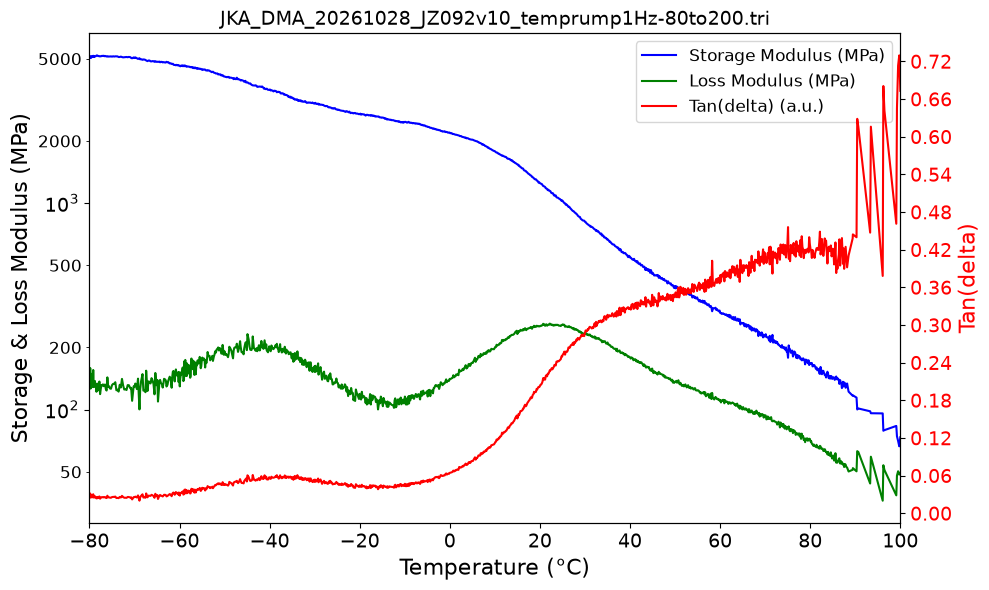

In [67]:
fig, ax1 = plt.subplots(figsize=(fig_width, fig_height))
fig.patch.set_facecolor('white')
ax1.set_facecolor('white')

lines_and_labels = []

# Plot each parameter based on the configuration list
for col_name, legend_label, scale, color in parameters_to_plot:
    if col_name in df_plot.columns:
        if col_name == 'Tan(delta)':
            ax2 = ax1.twinx()
            line = ax2.plot(df_plot[x_axis], df_plot[col_name], color=color, label=legend_label)
            ax2.set_ylabel('Tan(delta)', color=color, fontsize=axis_label_size)
            ax2.tick_params(axis='y', labelcolor=color, labelsize=tick_number_size)
            ax2.yaxis.set_major_locator(ticker.MaxNLocator(nbins=tan_delta_divisions))
            if scale == 'log':
                ax2.set_yscale('log')
            lines_and_labels.append(line[0])
        else:
            if scale == 'log':
                line = ax1.semilogy(df_plot[x_axis], df_plot[col_name], color=color, label=legend_label)
            else:
                line = ax1.plot(df_plot[x_axis], df_plot[col_name], color=color, label=legend_label)
            lines_and_labels.append(line[0])

# Main Y-Axis formatting
ax1.set_ylabel('Storage & Loss Modulus (MPa)', fontsize=axis_label_size)
ax1.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs=(2.0, 5.0)))
ax1.yaxis.set_minor_formatter(ticker.FuncFormatter(lambda y, _: '{:g}'.format(y)))

# X-Axis formatting
ax1.set_xlabel(f'{x_axis} (°C)', fontsize=axis_label_size)
ax1.tick_params(axis='both', which='major', labelsize=tick_number_size)
ax1.tick_params(axis='y', which='minor', labelsize=tick_number_size - 2)
ax1.set_xlim([x_min, x_max])

# Title using the original file name
display_title = metadata.get('File name', filename).split('\\')[-1]
ax1.set_title(display_title, fontsize=title_size)

# Unified Legend
labels = [l.get_label() for l in lines_and_labels]
ax1.legend(lines_and_labels, labels, loc='best', fontsize=legend_size)
plt.tight_layout()

# Save and Show
graph_image_name = filename.rsplit('.', 1)[0] + '_graph.jpg'
fig.savefig(graph_image_name, format='jpg', dpi=300, bbox_inches='tight', facecolor='white')
print(f"Graph successfully saved as: {graph_image_name}")

plt.show()